# Email Phishing Text Classifier Training
Model: TF-IDF + Logistic Regression
We train a text classifier to detect phishing emails using TF-IDF vectorization and Logistic Regression.

# TF - IDF

TF-IDF = Term Frequency - Inverse Document Frequency
Breaking it down simply:

TF (Term Frequency)

How often a word appears in ONE email
Example: if "verify" appears 5 times in an email → high TF
More occurrences = more important to that email

IDF (Inverse Document Frequency)

How rare a word is across ALL emails
Example: "the", "and", "is" appear in every email → low IDF (not useful)
Example: "verify", "account", "password" appear in few emails → high IDF (very useful!)


In [3]:
# Cell 2 — Configuration
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             classification_report)
import joblib
import os

# Dataset
DATA_PATH = 'phishing_email.csv'
TEXT_COL  = 'text_combined'
LABEL_COL = 'label'

# Train/Test split
TEST_SIZE    = 0.2
RANDOM_STATE = 42

# TF-IDF hyperparameters
NGRAM_RANGE   = (1, 2)
MAX_FEATURES  = 30000
SUBLINEAR_TF  = True

# Model hyperparameters
MAX_ITER     = 1000
CLASS_WEIGHT = 'balanced'

# Output paths
MODEL_DIR        = '../backend/models'
TFIDF_PATH       = os.path.join(MODEL_DIR, 'tfidf.pkl')
TEXT_MODEL_PATH  = os.path.join(MODEL_DIR, 'text_model.pkl')

print("All variables declared!")

All variables declared!


In [5]:
# Cell 2 — Load Dataset
df = pd.read_csv('phishing_email.csv')
print("Shape:", df.shape)
print("\nLabel distribution:")
print(df['label'].value_counts())
df.head()

Shape: (82486, 2)

Label distribution:
label
1    42891
0    39595
Name: count, dtype: int64


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


## Data Cleaning
We remove null values and normalize text to lowercase for consistent vectorization.

In [6]:
# Cell 4 — Clean Data
df = df.dropna(subset=[TEXT_COL, LABEL_COL])
df[TEXT_COL] = df[TEXT_COL].astype(str).str.lower().str.strip()

print(f"After cleaning: {df.shape}")
print(f"Null values remaining: {df.isnull().sum().sum()}")

After cleaning: (82486, 2)
Null values remaining: 0


## Train/Test Split
We split the dataset into 80% training and 20% testing using stratified sampling to preserve class distribution.

In [7]:
# Cell 5 — Train/Test Split
X = df[TEXT_COL]
y = df[LABEL_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples:  {len(X_test)}")
print(f"\nTrain label distribution:")
print(y_train.value_counts())
print(f"\nTest label distribution:")
print(y_test.value_counts())

Training samples: 65988
Testing samples:  16498

Train label distribution:
label
1    34312
0    31676
Name: count, dtype: int64

Test label distribution:
label
1    8579
0    7919
Name: count, dtype: int64


## TF-IDF Vectorization
We convert raw email text into numerical feature vectors using TF-IDF with unigrams and bigrams.

In [8]:
# Cell 6 — TF-IDF Vectorization
tfidf = TfidfVectorizer(
    ngram_range=NGRAM_RANGE,
    max_features=MAX_FEATURES,
    sublinear_tf=SUBLINEAR_TF
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f"Vocabulary size:       {len(tfidf.vocabulary_):,}")
print(f"Training matrix shape: {X_train_tfidf.shape}")
print(f"Testing matrix shape:  {X_test_tfidf.shape}")

Vocabulary size:       30,000
Training matrix shape: (65988, 30000)
Testing matrix shape:  (16498, 30000)


# Why bigrams matter for phishing detection:
"click" alone is normal \
"click here" is suspicious \
"account" alone is normal \
"verify account" is suspicious! 



## Model Training
We train a Logistic Regression classifier with balanced class weights to handle any class imbalance.

In [9]:
# Cell 7 — Train Model
model = LogisticRegression(
    class_weight=CLASS_WEIGHT,
    max_iter=MAX_ITER,
    random_state=RANDOM_STATE
)

model.fit(X_train_tfidf, y_train)
print("Model training complete!")

Model training complete!


## Model Evaluation
We evaluate the trained model on the held-out test set using Accuracy, Precision, Recall, F1 Score and ROC-AUC.

In [10]:
# Cell 8 — Evaluate Model
y_pred = model.predict(X_test_tfidf)
y_prob = model.predict_proba(X_test_tfidf)[:, 1]

print("="*45)
print("         MODEL EVALUATION RESULTS")
print("="*45)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")
print("="*45)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Ham', 'Phishing']))

         MODEL EVALUATION RESULTS
Accuracy:  0.9848
Precision: 0.9855
Recall:    0.9853
F1 Score:  0.9854
ROC-AUC:   0.9985

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.98      0.98      7919
    Phishing       0.99      0.99      0.99      8579

    accuracy                           0.98     16498
   macro avg       0.98      0.98      0.98     16498
weighted avg       0.98      0.98      0.98     16498



## Results 

98.48% Accuracy → correctly classifies 98 out of 100 emails \
98.55% Precision → when it says phishing, it's right 98.55% of the time \
98.53% Recall → catches 98.53% of all phishing emails \
98.54% F1 → perfect balance between precision and recall \
99.85% ROC-AUC → near perfect discrimination between ham and phishing 

## Confusion Matrix
Visual representation of model predictions vs actual labels.

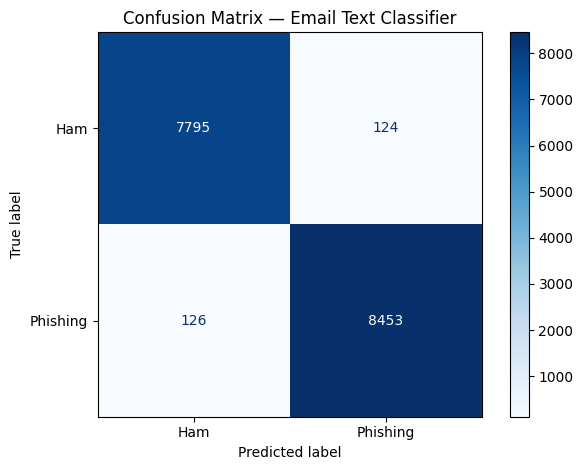

In [12]:
# Cell 9 — Confusion Matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ham', 'Phishing'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix — Email Text Classifier')
plt.tight_layout()
plt.show()

## Top Influential Words
We extract the top TF-IDF tokens that most strongly indicate phishing or ham using Logistic Regression coefficients.

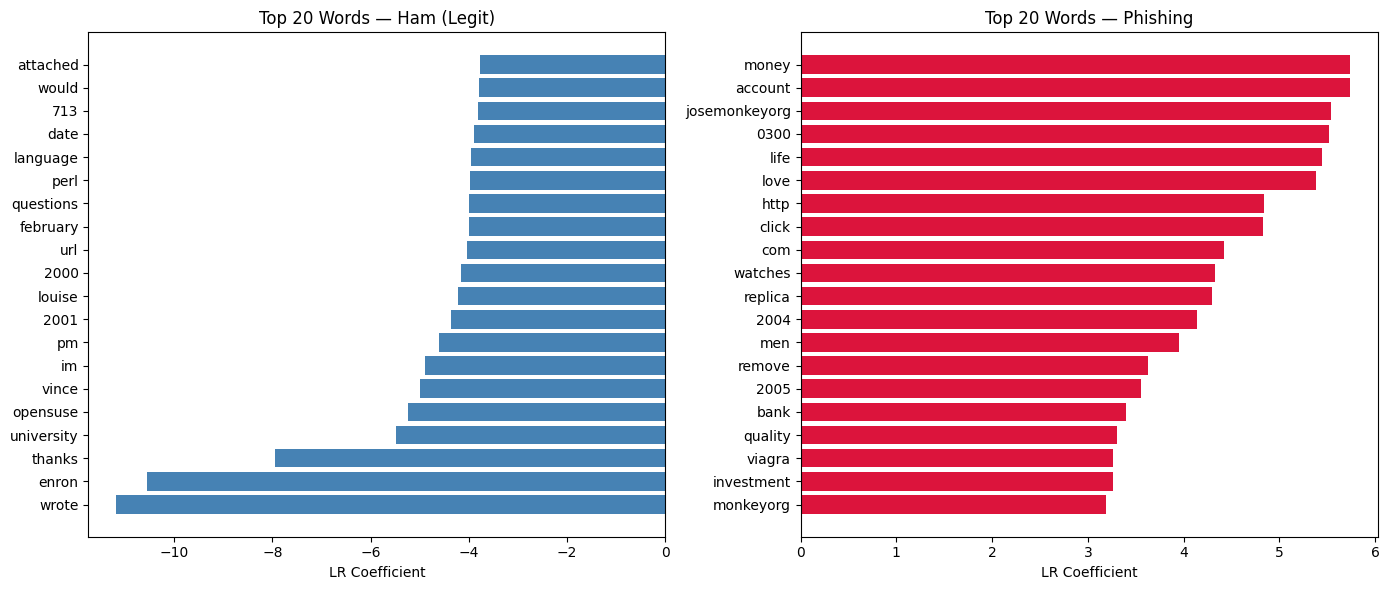

In [13]:
# Cell 10 — Top Influential Words
import matplotlib.pyplot as plt
import numpy as np

feature_names = np.array(tfidf.get_feature_names_out())
coefficients = model.coef_[0]

# Top 20 phishing words
top_phishing_idx = coefficients.argsort()[-20:]
top_ham_idx = coefficients.argsort()[:20]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(feature_names[top_ham_idx], coefficients[top_ham_idx], color='steelblue')
axes[0].set_title('Top 20 Words — Ham (Legit)')
axes[0].set_xlabel('LR Coefficient')

axes[1].barh(feature_names[top_phishing_idx], coefficients[top_phishing_idx], color='crimson')
axes[1].set_title('Top 20 Words — Phishing')
axes[1].set_xlabel('LR Coefficient')

plt.tight_layout()
plt.show()

## ROC Curve
The ROC curve visualizes the tradeoff between true positive rate and false positive rate across all thresholds.

## Save Models
We save the trained TF-IDF vectorizer and Logistic Regression model as .pkl files for use in the Flask backend.

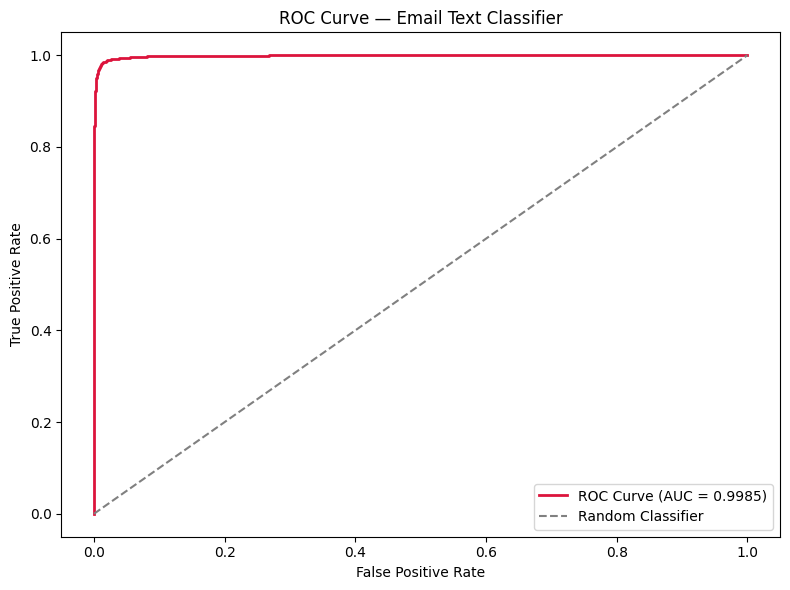

In [15]:
# Cell 12 — ROC Curve
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='crimson', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Email Text Classifier')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Why TF-IDF + Logistic Regression?

### Why TF-IDF?
TF-IDF (Term Frequency — Inverse Document Frequency) converts raw email text into numerical feature vectors. It rewards words that appear frequently in a specific email but rarely across all emails, making it ideal for capturing distinctive phishing vocabulary such as "verify account" or "click here". Using bigrams (ngram_range=(1,2)) further captures suspicious two-word phrases that single words would miss.

### Why Logistic Regression?
Logistic Regression was selected for three key reasons:
1. **Speed** — inference takes microseconds, satisfying our real-time latency requirement of p95 ≤ 250ms
2. **Explainability** — model coefficients directly reveal which words contributed most to a prediction, enabling fast explainability without SHAP
3. **Performance** — achieved 98.48% accuracy and 99.85% ROC-AUC on the test set, demonstrating that deep learning is unnecessary for this task

### Why NOT other models?
| Model | Reason Rejected |
|-------|----------------|
| BERT/Transformers | Too slow for real-time inference, explicitly banned by project constraints |
| Random Forest | Slower inference, less interpretable on text features |
| SVM | Similar performance but slower to train and less probabilistic |
| Neural Networks | Overkill, high latency, poor explainability |

In [14]:
# Cell 11 — Save Models
import os
import joblib

os.makedirs('../backend/models', exist_ok=True)

joblib.dump(tfidf, '../backend/models/tfidf.pkl')
joblib.dump(model, '../backend/models/text_model.pkl')

print("✅ Saved: tfidf.pkl")
print("✅ Saved: text_model.pkl")
print(f"\nModel saved to: ../backend/models/")

✅ Saved: tfidf.pkl
✅ Saved: text_model.pkl

Model saved to: ../backend/models/
